In [1]:
"""
Análisis de resultados unimodales del Joint Search.

Entradas esperadas (en el directorio de trabajo):
    {Modalidad}_resumen_maestro_joint.csv       — una por modalidad
    {Modalidad}/importancia_ROIs_{Modelo}_s{S}.csv  — una por modelo x semilla

Salidas (en resultados_unimodales/):
    tablas/
        resumen_stats_{Modalidad}.csv           — media ± std por algoritmo
        resumen_comparativa_modalidades.csv     — comparativa entre modalidades
        selector_frecuencia_{Modalidad}.csv     — frecuencia de selector ganador
        k_frecuencia_{Modalidad}.csv            — frecuencia de k ganador
    figuras/
        01_cv_test_acc_{Modalidad}.png          — CV vs Test Acc por algoritmo
        03_comparativa_modalidades.png          — boxplot comparativa entre modalidades
        04_varianza_semillas_{Modalidad}.png    — variabilidad entre semillas
        05_selector_k_{Modalidad}.png           — distribución selector y k
        06_importancia_rois_{Modalidad}.png     — top ROIs agregados entre semillas
"""

'\nAnálisis de resultados unimodales del Joint Search.\n\nEntradas esperadas (en el directorio de trabajo):\n    {Modalidad}_resumen_maestro_joint.csv       — una por modalidad\n    {Modalidad}/importancia_ROIs_{Modelo}_s{S}.csv  — una por modelo x semilla\n\nSalidas (en resultados_unimodales/):\n    tablas/\n        resumen_stats_{Modalidad}.csv           — media ± std por algoritmo\n        resumen_comparativa_modalidades.csv     — comparativa entre modalidades\n        selector_frecuencia_{Modalidad}.csv     — frecuencia de selector ganador\n        k_frecuencia_{Modalidad}.csv            — frecuencia de k ganador\n    figuras/\n        01_cv_test_acc_{Modalidad}.png          — CV vs Test Acc por algoritmo\n        03_comparativa_modalidades.png          — boxplot comparativa entre modalidades\n        04_varianza_semillas_{Modalidad}.png    — variabilidad entre semillas\n        05_selector_k_{Modalidad}.png           — distribución selector y k\n        06_importancia_rois_{Modali

In [2]:
from copy import copy
import os
import re
import ast
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from matplotlib.lines import Line2D

In [3]:
# ── Configuración ──────────────────────────────────────────────────────────────
MODALIDADES  = ['Morfológicos', 'Metabólicos', 'DTI']
ALGORITMOS   = ['ElasticNet', 'KNN', 'SVM', 'RF', 'CatBoost', 'MLP']
METRICAS     = ['CV_Acc', 'Test_Acc', 'Precision', 'Recall', 'F1']
SEEDS        = [7, 14, 21, 28, 35]
OUT_DIR      = 'resultados_unimodales'
PALETTE      = sns.color_palette('tab10', n_colors=len(ALGORITMOS))
COLOR_MAP    = dict(zip(ALGORITMOS, PALETTE))
MOD_COLORS   = {'Morfológicos': '#DD8452', 'Metabólicos': '#55A868', 'DTI': '#4C72B0'}
# Paleta anatómica con lateralidad
COLORES_ROI = {
    'amig_der': '#E84545',  # rojo intenso
    'amig_izq': '#F4A0A0',  # rojo claro
    'hip_der':  '#2E86AB',  # azul intenso
    'hip_izq':  '#90CAE4',  # azul claro
    'tal_der':  '#4CAF50',  # verde intenso
    'tal_izq':  '#A8D8A8',  # verde claro
}
os.makedirs(f'{OUT_DIR}/tablas',  exist_ok=True)
os.makedirs(f'{OUT_DIR}/figuras', exist_ok=True)

# ── Helpers ────────────────────────────────────────────────────────────────────

def cargar_resumen(modo):
    path = f'{modo}_resumen_maestro_joint.csv'
    if not os.path.exists(path):
        print(f'  ⚠️  No encontrado: {path}')
        return None
    df = pd.read_csv(path)
    df['Modalidad'] = modo
    return df


def parsear_params(params_str):
    """Extrae hiperparámetros relevantes del string de Params."""
    try:
        # Limpia el string de objetos sklearn no serializables
        clean = re.sub(r"SelectKBest\([^)]*\)", "None", params_str)
        clean = re.sub(r"SelectFromModel\([^)]*\)", "None", clean)
        d = ast.literal_eval(clean)
        # Quitar claves de selector (ya están en columnas propias)
        return {k: v for k, v in d.items()
                if k not in ('selector', 'selector__k', 'selector__max_features')}
    except Exception:
        return {}


def cargar_importancias(modo):
    """
    Carga todos los CSVs de importancia de ROIs de una modalidad
    y devuelve un DataFrame con la importancia media por ROI.
    """
    pattern = f'{modo}/importancia_ROIs_*_s*.csv'
    files = glob.glob(pattern)
    if not files:
        print(f'  ⚠️  Sin archivos de importancia en {modo}/')
        return None

    partes = []
    for f in files:
        df = pd.read_csv(f, index_col=0)
        # Normalizar a [0,1] dentro de cada run
        imp_min = df['Importancia'].min()
        imp_max = df['Importancia'].max()
        if imp_max > imp_min:
            df['Importancia'] = (df['Importancia'] - imp_min) / (imp_max - imp_min)
        partes.append(df)

    all_imp = pd.concat(partes, ignore_index=True)
    imp_media = (all_imp.groupby('ROI')['Importancia'].mean().reset_index())
    imp_media = imp_media.sort_values(by='Importancia', ascending=False)
    # Guardamos el CSV por modalidad
    ruta_guardado = f'{modo}/biomarcadores_consolidados_{modo}.csv'
    imp_media.to_csv(ruta_guardado, index=False)
    print(f'  ✅ Archivo consolidado guardado en: {ruta_guardado}')
    return all_imp

import glob
import pandas as pd


def get_color_roi(roi_name):
    """Extrae estructura y lateralidad del nombre del ROI."""
    for key, color in COLORES_ROI.items():
        if key in roi_name:
            return color
    return '#BBBBBB'  # gris para ROIs no identificados


def figura_top10_todas_modalidades(out_dir, modalidades):
    """
    Panel 3 columnas: top 10 ROIs por modalidad, coloreados por
    estructura anatómica y lateralidad.
    """
    fig, axes = plt.subplots(1, len(modalidades), figsize=(16, 6))

    for ax, modo in zip(axes, modalidades):
        all_imp = cargar_importancias(modo)   # ya normalizada [0,1] por run
        if all_imp is None:
            ax.set_visible(False)
            continue

        imp_media = (all_imp.groupby('ROI')['Importancia']
                     .mean()
                     .sort_values(ascending=False)
                     .head(10))

        colores = [get_color_roi(roi) for roi in imp_media.index[::-1]]

        ax.barh(imp_media.index[::-1], imp_media.values[::-1],
                color=colores, alpha=0.92, edgecolor='white', linewidth=0.5)

        ax.set_xlim(0, 1)
        ax.set_xlabel('Importancia media norm.', fontsize=10)
        ax.set_title(modo, fontsize=12, fontweight='bold')
        ax.grid(axis='x', alpha=0.25)
        ax.tick_params(axis='y', labelsize=9)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

    # Leyenda compartida
    legend_elements = [
        mpatches.Patch(color='#E84545', label='Amígdala der.'),
        mpatches.Patch(color='#F4A0A0', label='Amígdala izq.'),
        mpatches.Patch(color='#2E86AB', label='Hipocampo der.'),
        mpatches.Patch(color='#90CAE4', label='Hipocampo izq.'),
        mpatches.Patch(color='#4CAF50', label='Tálamo der.'),
        mpatches.Patch(color='#A8D8A8', label='Tálamo izq.'),
        mpatches.Patch(color='#BBBBBB', label='Otros'),
    ]
    fig.legend(handles=legend_elements,
               loc='lower center', ncol=4,
               fontsize=9, frameon=False,
               bbox_to_anchor=(0.5, -0.08))

    plt.suptitle('Top 10 ROIs por modalidad\n(importancia normalizada [0,1], coloreada por región y lateralidad)',
                 fontsize=12, y=1.02)
    plt.tight_layout()
    plt.savefig(f'{out_dir}/figuras/09_top10_rois_todas_modalidades.png',
                dpi=150, bbox_inches='tight')
    #plt.close()
    print('  ✅ Fig 9 guardada: Top 10 ROIs todas las modalidades')

def figura_selector_k_todas_modalidades(out_dir, modalidades, dfs):
    """
    Panel 3 filas × 2 columnas: selector ganador y k por modalidad.
    dfs: dict {modalidad: dataframe}
    """
    fig, axes = plt.subplots(len(modalidades), 2,
                             figsize=(12, 4 * len(modalidades)))

    short_labels = {
        'KBest_f_classif':                    'ANOVA',
        'KBest_mutual_info_classif':          'MI',
        'FromModel_RandomForestClassifier':   'RF-SFM',
    }
    col_sel = '#4C72B0'
    col_k   = '#DD8452'

    for i, modo in enumerate(modalidades):
        df = dfs.get(modo)
        ax_sel, ax_k = axes[i]

        if df is None:
            ax_sel.set_visible(False)
            ax_k.set_visible(False)
            continue

        # ── Selector ──────────────────────────────────────────────
        sel_counts = df['Selector'].value_counts()
        labels = [short_labels.get(s, s) for s in sel_counts.index]
        ax_sel.bar(labels, sel_counts.values, color=col_sel, alpha=0.85)
        ax_sel.set_title(f'{modo} — Selector', fontsize=11, fontweight='bold')
        ax_sel.set_ylabel('Frecuencia', fontsize=10)
        ax_sel.grid(axis='y', alpha=0.3)
        ax_sel.spines['top'].set_visible(False)
        ax_sel.spines['right'].set_visible(False)
        # Anotar conteo encima de cada barra
        for bar, val in zip(ax_sel.patches, sel_counts.values):
            ax_sel.text(bar.get_x() + bar.get_width()/2,
                        bar.get_height() + 0.1,
                        str(val), ha='center', va='bottom', fontsize=9)

        # ── k features ────────────────────────────────────────────
        k_counts = df['k'].value_counts().sort_index()
        ax_k.bar(k_counts.index.astype(str), k_counts.values,
                 color=col_k, alpha=0.85)
        ax_k.set_title(f'{modo} — k features', fontsize=11, fontweight='bold')
        ax_k.set_ylabel('Frecuencia', fontsize=10)
        ax_k.set_xlabel('k', fontsize=10)
        ax_k.grid(axis='y', alpha=0.3)
        ax_k.spines['top'].set_visible(False)
        ax_k.spines['right'].set_visible(False)
        for bar, val in zip(ax_k.patches, k_counts.values):
            ax_k.text(bar.get_x() + bar.get_width()/2,
                      bar.get_height() + 0.1,
                      str(val), ha='center', va='bottom', fontsize=9)

    plt.suptitle('Selector y número de features seleccionadas por modalidad',
                 fontsize=13, y=1.01)
    plt.tight_layout()
    plt.savefig(f'{out_dir}/figuras/05_selector_k_todas_modalidades.png',
                dpi=150, bbox_inches='tight')
    #plt.close()
    print('  ✅ Fig 5 guardada: Selector y k — panel unificado')

def figura_selector_k_unificada(out_dir, modalidades, dfs):
    MOD_COLORS = {
        'DTI':          '#4C72B0',
        'Metabólicos':  '#55A868',
        'Morfológicos': '#DD8452',
    }
    short_labels = {
        'KBest_f_classif':                  'ANOVA',
        'KBest_mutual_info_classif':        'MI',
        'FromModel_RandomForestClassifier': 'RF-SFM',
    }

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
    width = 0.25

    # ── Panel A: Selector ─────────────────────────────────────────────────────
    all_selectors = []
    for df in dfs.values():
        all_selectors.extend(df['Selector'].unique().tolist())
    all_selectors = [short_labels.get(s, s)
                     for s in sorted(set(all_selectors))]
    x = np.arange(len(all_selectors))

    for i, modo in enumerate(modalidades):
        df = dfs.get(modo)
        if df is None: continue
        sel_mapped = df['Selector'].map(short_labels).fillna(df['Selector'])
        counts = [sel_mapped.value_counts().get(s, 0) for s in all_selectors]
        bars = ax1.bar(x + i * width, counts, width,
                       label=modo, color=MOD_COLORS[modo], alpha=0.87)
        for bar, val in zip(bars, counts):
            if val > 0:
                ax1.text(bar.get_x() + bar.get_width() / 2,
                         bar.get_height() + 0.1,
                         str(val), ha='center', va='bottom', fontsize=9)

    ax1.set_xticks(x + width)
    ax1.set_xticklabels(all_selectors, fontsize=11)
    ax1.set_ylabel('Frecuencia (modelos × semillas)', fontsize=11)
    ax1.set_title('Selector ganador por modalidad', fontsize=13)
    ax1.legend(title='Modalidad', fontsize=10)
    ax1.grid(axis='y', alpha=0.3)
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)

    # ── Panel B: k features ───────────────────────────────────────────────────
    all_k = sorted(set(k for df in dfs.values() for k in df['k'].unique()))
    x = np.arange(len(all_k))

    for i, modo in enumerate(modalidades):
        df = dfs.get(modo)
        if df is None: continue
        counts = [df['k'].value_counts().get(k, 0) for k in all_k]
        bars = ax2.bar(x + i * width, counts, width,
                       label=modo, color=MOD_COLORS[modo], alpha=0.87)
        for bar, val in zip(bars, counts):
            if val > 0:
                ax2.text(bar.get_x() + bar.get_width() / 2,
                         bar.get_height() + 0.1,
                         str(val), ha='center', va='bottom', fontsize=9)

    ax2.set_xticks(x + width)
    ax2.set_xticklabels([str(k) for k in all_k], fontsize=11)
    ax2.set_xlabel('k features seleccionadas', fontsize=11)
    ax2.set_ylabel('Frecuencia (modelos × semillas)', fontsize=11)
    ax2.set_title('k features seleccionadas por modalidad', fontsize=13)
    ax2.legend(title='Modalidad', fontsize=10)
    ax2.grid(axis='y', alpha=0.3)
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)

    plt.tight_layout()
    plt.savefig(f'{out_dir}/figuras/05_selector_k_unificado.png',
                dpi=150, bbox_inches='tight')
    #plt.close()
    print('  ✅ Fig 5 guardada: Selector y k unificados')


In [4]:
# ══════════════════════════════════════════════════════════════════════════════
# ANÁLISIS POR MODALIDAD
# ══════════════════════════════════════════════════════════════════════════════

todos = []
dfs_por_modalidad = {}

MOD_TRANSLATE = {
    'Morfológicos': 'MRI',
    'Metabólicos':  'PET',
    'DTI':          'DTI'
}

for modo in MODALIDADES:
    print(f'\n{"─"*55}')
    print(f'  Procesando: {modo}')
    print(f'{"─"*55}')

    df = cargar_resumen(modo)
    if df is None:
        continue
    dfs_por_modalidad[modo] = df
    todos.append(df)

    # ── 1. Tabla: media ± std por algoritmo ───────────────────────────────────
    stats_rows = []
    for algo, grp in df.groupby('Modelo'):
        row = {'Modelo': algo}
        for m in METRICAS:
            if m in grp.columns:
                row[f'{m}_mean'] = round(grp[m].mean(), 4)
                row[f'{m}_std']  = round(grp[m].std(),  4)
        # Selector más frecuente
        row['Selector_top'] = grp['Selector'].mode().iloc[0]
        row['k_top']        = int(grp['k'].mode().iloc[0])
        stats_rows.append(row)

    df_stats = pd.DataFrame(stats_rows).sort_values('CV_Acc_mean', ascending=False)
    df_stats.to_csv(f'{OUT_DIR}/tablas/resumen_stats_{modo}.csv', index=False)
    print(f'  ✅ Tabla stats guardada')
    print(df_stats[['Modelo','CV_Acc_mean','CV_Acc_std',
                    'Test_Acc_mean','Test_Acc_std','F1_mean']].to_string(index=False))

    # ── 2. Tabla: frecuencia de selector y k ──────────────────────────────────
    df['Selector'].value_counts().reset_index().rename(
        columns={'index':'Selector','Selector':'Count'}).to_csv(
        f'{OUT_DIR}/tablas/selector_frecuencia_{modo}.csv', index=False)
    df['k'].value_counts().reset_index().rename(
        columns={'index':'k','k':'Count'}).to_csv(
        f'{OUT_DIR}/tablas/k_frecuencia_{modo}.csv', index=False)






───────────────────────────────────────────────────────
  Procesando: Morfológicos
───────────────────────────────────────────────────────
  ✅ Tabla stats guardada
    Modelo  CV_Acc_mean  CV_Acc_std  Test_Acc_mean  Test_Acc_std  F1_mean
ElasticNet       0.7286      0.0433         0.6778        0.0913   0.6537
       KNN       0.6952      0.0516         0.7333        0.0465   0.7172
       SVM       0.6857      0.0310         0.7333        0.1204   0.7254
        RF       0.6619      0.0261         0.6889        0.0497   0.6622
       MLP       0.6571      0.0433         0.6889        0.0633   0.6700
  CatBoost       0.6286      0.0319         0.6444        0.0843   0.6212

───────────────────────────────────────────────────────
  Procesando: Metabólicos
───────────────────────────────────────────────────────
  ✅ Tabla stats guardada
    Modelo  CV_Acc_mean  CV_Acc_std  Test_Acc_mean  Test_Acc_std  F1_mean
ElasticNet       0.6238      0.0458         0.5556        0.0878   0.5510
     

In [5]:
# ══════════════════════════════════════════════════════════════════════════════
# ANÁLISIS COMPARATIVO ENTRE MODALIDADES
# ══════════════════════════════════════════════════════════════════════════════

#if len(todos) > 1:
print(f'\n{"═"*55}')
print('Análisis comparativo entre modalidades')
print(f'{"═"*55}')

df_all = pd.concat(todos, ignore_index=True)

# ── Tabla comparativa (Formato Mean ± Std) ───────────────────────────
comp_rows = []
for modo in MODALIDADES:
    sub = df_all[df_all['Modalidad'] == modo]
    if sub.empty: continue
    
    modo_en = MOD_TRANSLATE.get(modo, modo)
    row = {'Modality': modo_en}
    
    for metric in METRICAS:
        if metric in sub.columns:
            mean_val = sub[metric].mean()
            std_val  = sub[metric].std()
            # Formateamos a 4 decimales con el símbolo ±
            row[metric] = f"{mean_val:.4f} ± {std_val:.4f}"
            
    comp_rows.append(row)

df_comp = pd.DataFrame(comp_rows)
df_comp.to_csv(f'{OUT_DIR}/tablas/resumen_comparativa_modalidades.csv', index=False)

print('\n  Comparativa Global (Mean ± Std):')
print(df_comp.to_string(index=False))



═══════════════════════════════════════════════════════
Análisis comparativo entre modalidades
═══════════════════════════════════════════════════════

  Comparativa Global (Mean ± Std):
Modality          CV_Acc        Test_Acc       Precision          Recall              F1
     MRI 0.6762 ± 0.0479 0.6944 ± 0.0796 0.7062 ± 0.1003 0.6944 ± 0.0796 0.6750 ± 0.0873
     PET 0.6024 ± 0.0425 0.5759 ± 0.0751 0.5883 ± 0.0863 0.5759 ± 0.0751 0.5676 ± 0.0788
     DTI 0.8230 ± 0.0304 0.7778 ± 0.0934 0.7881 ± 0.1183 0.7778 ± 0.0934 0.7657 ± 0.1088


In [6]:
# Cargar la tabla que acabamos de generar
df_tabla = df_comp
# Seleccionar y renombrar las columnas con la notación matemática correcta
df_latex = df_tabla[['Modality', 'CV_Acc', 'Test_Acc', 'Precision', 'Recall', 'F1']].copy()
df_latex.columns = ['Modality', 'Tr. Acc.', 'Accuracy', 'Precision', 'Recall', 'F1']

# Exportar directamente a un archivo .tex listo para incluir o copiar
codigo_latex = df_latex.to_latex(
    index=False,
    float_format="%.4f",       # Redondea automáticamente todos los decimales a 4 posiciones
    bold_rows=False,
    column_format='lccccc',   # Alineación de columnas (l=left, c=center)
    caption='Resultados unimodales agregados para 6 modelos y 5 repeticiones.',
    label='tab:resumen_unimodales',
    position='htbp',
    na_rep='—'                 # Reemplaza los valores vacíos/NaN por la raya formal
)

#with open(f'{OUT_DIR}/tablas/tabla_resultados.tex', 'w', encoding='utf-8') as f:
#    f.write(codigo_latex)
#print("✅ Código LaTeX exportado automáticamente de forma nativa.")
print(codigo_latex)

\begin{table}[htbp]
\caption{Resultados unimodales agregados para 6 modelos y 5 repeticiones.}
\label{tab:resumen_unimodales}
\begin{tabular}{lccccc}
\toprule
Modality & Tr. Acc. & Accuracy & Precision & Recall & F1 \\
\midrule
MRI & 0.6762 ± 0.0479 & 0.6944 ± 0.0796 & 0.7062 ± 0.1003 & 0.6944 ± 0.0796 & 0.6750 ± 0.0873 \\
PET & 0.6024 ± 0.0425 & 0.5759 ± 0.0751 & 0.5883 ± 0.0863 & 0.5759 ± 0.0751 & 0.5676 ± 0.0788 \\
DTI & 0.8230 ± 0.0304 & 0.7778 ± 0.0934 & 0.7881 ± 0.1183 & 0.7778 ± 0.0934 & 0.7657 ± 0.1088 \\
\bottomrule
\end{tabular}
\end{table}



In [7]:
# ── Tabla comparativa (Formato Mean ± Std por Modalidad y Modelo) ─────
comp_rows = []

for modo in MODALIDADES:
    sub_modo = df_all[df_all['Modalidad'] == modo]
    if sub_modo.empty: continue
    
    modo_en = MOD_TRANSLATE.get(modo, modo)
    
    # Identificamos los modelos que existen dentro de esta modalidad
    modelos_presentes = sub_modo['Modelo'].unique()
    
    for modelo in modelos_presentes:
        # Filtramos solo los datos de este modelo (las 5 semillas)
        sub_modelo = sub_modo[sub_modo['Modelo'] == modelo]
        
        row = {
            'Modality': modo_en,
            'Model': modelo
        }
        
        for metric in METRICAS:
            if metric in sub_modelo.columns:
                mean_val = sub_modelo[metric].mean()
                std_val  = sub_modelo[metric].std()
                # Formateamos a 4 decimales con el símbolo ±
                row[metric] = f"{mean_val:.4f} ± {std_val:.4f}"
                
        comp_rows.append(row)

df_comp = pd.DataFrame(comp_rows)

# Opcional: Para asegurar que los modelos salgan en un orden consistente
df_comp['Model'] = pd.Categorical(df_comp['Model'], categories=ALGORITMOS, ordered=True)
df_comp = df_comp.sort_values(['Modality', 'Model'])

df_comp.to_csv(f'{OUT_DIR}/tablas/resumen_comparativa_modalidades_modelos.csv', index=False)

print('\n  Comparativa Global por Modalidad y Modelo (Mean ± Std):')
print(df_comp.to_string(index=False))


  Comparativa Global por Modalidad y Modelo (Mean ± Std):
Modality      Model          CV_Acc        Test_Acc       Precision          Recall              F1
     DTI ElasticNet 0.8238 ± 0.0398 0.7000 ± 0.0745 0.7018 ± 0.1475 0.7000 ± 0.0745 0.6762 ± 0.1057
     DTI        KNN 0.8095 ± 0.0168 0.7444 ± 0.1083 0.7454 ± 0.1093 0.7444 ± 0.1083 0.7423 ± 0.1098
     DTI        SVM 0.8476 ± 0.0319 0.8556 ± 0.0843 0.9054 ± 0.0438 0.8556 ± 0.0843 0.8421 ± 0.0977
     DTI         RF 0.8333 ± 0.0238 0.8444 ± 0.0465 0.8463 ± 0.0460 0.8444 ± 0.0465 0.8440 ± 0.0466
     DTI   CatBoost 0.8048 ± 0.0310 0.8222 ± 0.0248 0.8260 ± 0.0270 0.8222 ± 0.0248 0.8213 ± 0.0243
     DTI        MLP 0.8190 ± 0.0271 0.7000 ± 0.0633 0.7037 ± 0.1388 0.7000 ± 0.0633 0.6682 ± 0.0945
     MRI ElasticNet 0.7286 ± 0.0433 0.6778 ± 0.0913 0.6671 ± 0.1055 0.6778 ± 0.0913 0.6537 ± 0.1130
     MRI        KNN 0.6952 ± 0.0516 0.7333 ± 0.0465 0.7585 ± 0.0610 0.7333 ± 0.0465 0.7172 ± 0.0550
     MRI        SVM 0.6857 ± 0.0310 0.733

In [8]:
# Cargar la tabla que acabamos de generar
df_tabla = df_comp
# Seleccionar y renombrar las columnas con la notación matemática correcta
df_latex = df_tabla[['Modality', 'Model', 'CV_Acc', 'Test_Acc', 'Precision', 'Recall', 'F1']].copy()
df_latex.columns = ['Modality', 'Model', 'Tr. Acc.', 'Accuracy', 'Precision', 'Recall', 'F1']

# Exportar directamente a un archivo .tex listo para incluir o copiar
codigo_latex = df_latex.to_latex(
    index=False,
    float_format="%.4f",       # Redondea automáticamente todos los decimales a 4 posiciones
    bold_rows=False,
    column_format='llccccc',   # Alineación de columnas (l=left, c=center)
    caption='Resultados unimodales agregados para 5 repeticiones.',
    label='tab:resumen_unimodales_modelos',
    position='htbp',
    na_rep='—'                 # Reemplaza los valores vacíos/NaN por la raya formal
)

#with open(f'{OUT_DIR}/tablas/tabla_resultados.tex', 'w', encoding='utf-8') as f:
#    f.write(codigo_latex)
#print("✅ Código LaTeX exportado automáticamente de forma nativa.")
print(codigo_latex)

\begin{table}[htbp]
\caption{Resultados unimodales agregados para 5 repeticiones.}
\label{tab:resumen_unimodales_modelos}
\begin{tabular}{llccccc}
\toprule
Modality & Model & Tr. Acc. & Accuracy & Precision & Recall & F1 \\
\midrule
DTI & ElasticNet & 0.8238 ± 0.0398 & 0.7000 ± 0.0745 & 0.7018 ± 0.1475 & 0.7000 ± 0.0745 & 0.6762 ± 0.1057 \\
DTI & KNN & 0.8095 ± 0.0168 & 0.7444 ± 0.1083 & 0.7454 ± 0.1093 & 0.7444 ± 0.1083 & 0.7423 ± 0.1098 \\
DTI & SVM & 0.8476 ± 0.0319 & 0.8556 ± 0.0843 & 0.9054 ± 0.0438 & 0.8556 ± 0.0843 & 0.8421 ± 0.0977 \\
DTI & RF & 0.8333 ± 0.0238 & 0.8444 ± 0.0465 & 0.8463 ± 0.0460 & 0.8444 ± 0.0465 & 0.8440 ± 0.0466 \\
DTI & CatBoost & 0.8048 ± 0.0310 & 0.8222 ± 0.0248 & 0.8260 ± 0.0270 & 0.8222 ± 0.0248 & 0.8213 ± 0.0243 \\
DTI & MLP & 0.8190 ± 0.0271 & 0.7000 ± 0.0633 & 0.7037 ± 0.1388 & 0.7000 ± 0.0633 & 0.6682 ± 0.0945 \\
MRI & ElasticNet & 0.7286 ± 0.0433 & 0.6778 ± 0.0913 & 0.6671 ± 0.1055 & 0.6778 ± 0.0913 & 0.6537 ± 0.1130 \\
MRI & KNN & 0.6952 ± 0.0516 

  ✅ Fig 3 guardada: Comparativa modalidades


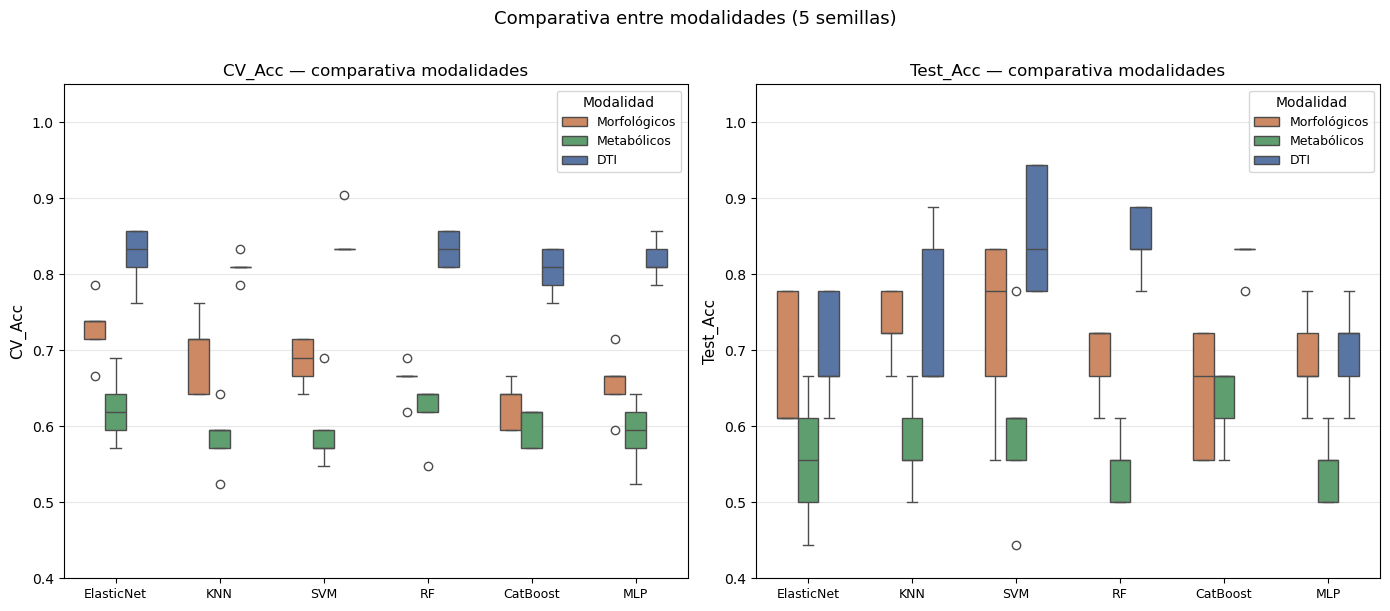

In [9]:
# ══════════════════════════════════════════════════════════════════════
# FIGURA 3 — Boxplot comparativa modalidades × algoritmo
# ══════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, metric in zip(axes, ['CV_Acc', 'Test_Acc']):
    sns.boxplot(data=df_all, x='Modelo', y=metric,
                hue='Modalidad', order=ALGORITMOS,
                palette=MOD_COLORS, width=0.6,
                hue_order=MODALIDADES, ax=ax)
    #ax.axhline(1/2, color='gray', linestyle=':', lw=1.2, label='Azar')
    ax.set_ylim(0.4, 1.05)
    ax.set_title(f'{metric} — comparativa modalidades', fontsize=12)
    ax.set_xlabel('')
    ax.set_ylabel(metric, fontsize=11)
    ax.legend(title='Modalidad', fontsize=9)
    ax.grid(axis='y', alpha=0.3)
    ax.tick_params(axis='x', labelsize=9)

plt.suptitle('Comparativa entre modalidades (5 semillas)', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/figuras/03_comparativa_modalidades.png',
            dpi=150, bbox_inches='tight')
#plt.close()
print('  ✅ Fig 3 guardada: Comparativa modalidades')



  ✅ Fig 3 guardada: Comparativa modalidades (Vertical)


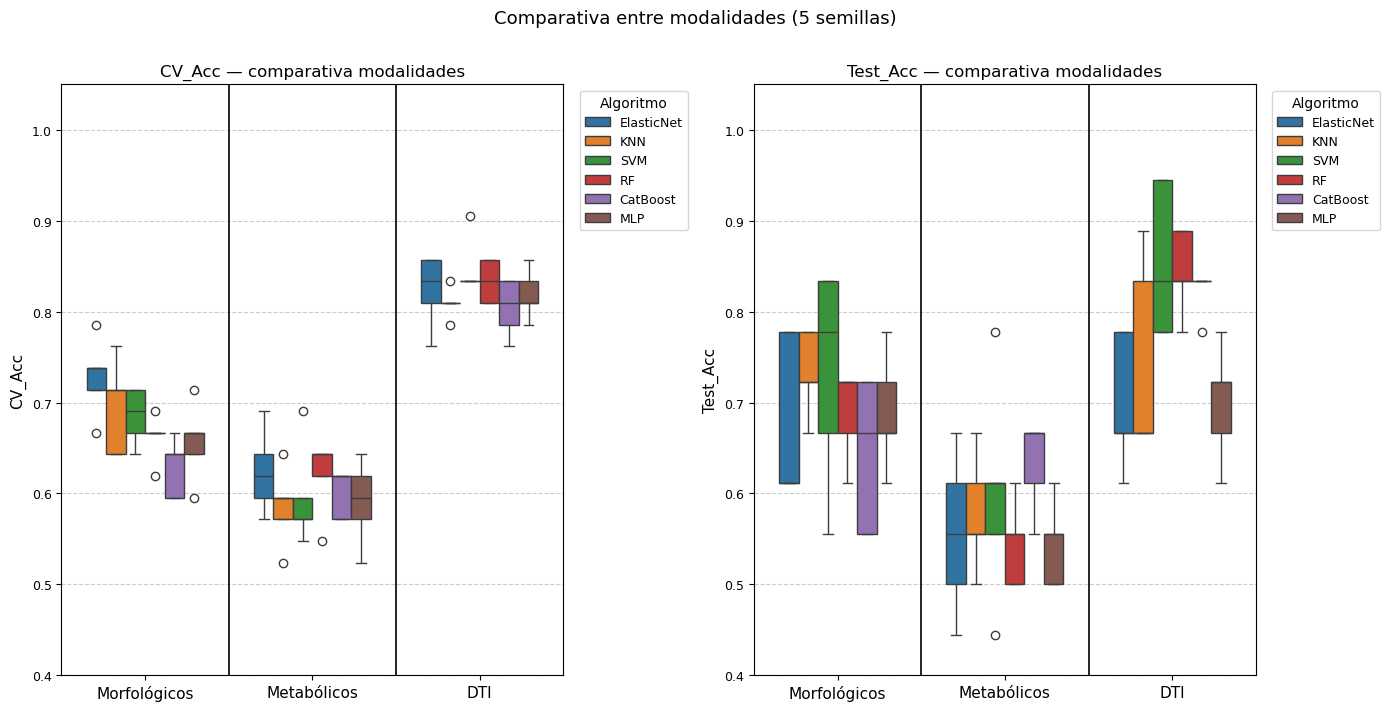

In [10]:
# ══════════════════════════════════════════════════════════════════════
# FIGURA 3 — Boxplot comparativa modalidades × algoritmo (Vertical)
# ══════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

for ax, metric in zip(axes, ['CV_Acc', 'Test_Acc']):
    # 1. Asignamos Modalidad en X y la métrica cuantitativa en Y para orientación vertical
    sns.boxplot(data=df_all, x='Modalidad', y=metric,
                hue='Modelo', order=MODALIDADES,
                hue_order=ALGORITMOS, width=0.7, ax=ax)
    
    # 2. El eje cuantitativo ahora es el Y
    ax.set_ylim(0.4, 1.05)
    ax.set_title(f'{metric} — comparativa modalidades', fontsize=12)
    ax.set_xlabel('') # Ocultamos la etiqueta "Modalidad" para limpiar la visualización
    ax.set_ylabel(metric, fontsize=11)
    
    # 3. Grid cuantitativo HORIZONTAL (líneas tenues para leer los valores en Y)
    ax.grid(axis='y', alpha=0.4, color='gray', linestyle='--')
    ax.set_axisbelow(True) # Envía las líneas del grid al fondo
    
    # 4. Líneas VERTICALES para separar cada modalidad (x=0.5 y x=1.5)
    ax.axvline(x=0.5, color='black', linewidth=1.2, linestyle='-')
    ax.axvline(x=1.5, color='black', linewidth=1.2, linestyle='-')

    # Ajuste visual de las etiquetas
    ax.tick_params(axis='x', labelsize=11)
    ax.tick_params(axis='y', labelsize=9)
    
    # 5. Leyenda visible en ambos gráficos
    ax.legend(title='Algoritmo', fontsize=9, bbox_to_anchor=(1.02, 1), loc='upper left')

plt.suptitle('Comparativa entre modalidades (5 semillas)', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/figuras/03_comparativa_modalidades.png',
            dpi=150, bbox_inches='tight')
#plt.close()
print('  ✅ Fig 3 guardada: Comparativa modalidades (Vertical)')

  ✅ Subfigure saved: resultados_unimodales/figuras/03_boxplot_morfológicos.png
  ✅ Subfigure saved: resultados_unimodales/figuras/03_boxplot_metabólicos.png
  ✅ Subfigure saved: resultados_unimodales/figuras/03_boxplot_dti.png


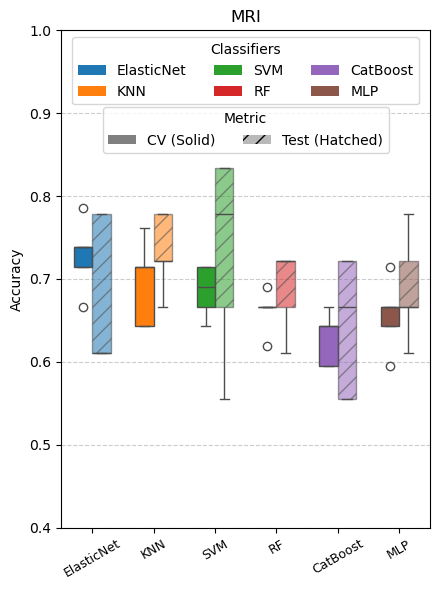

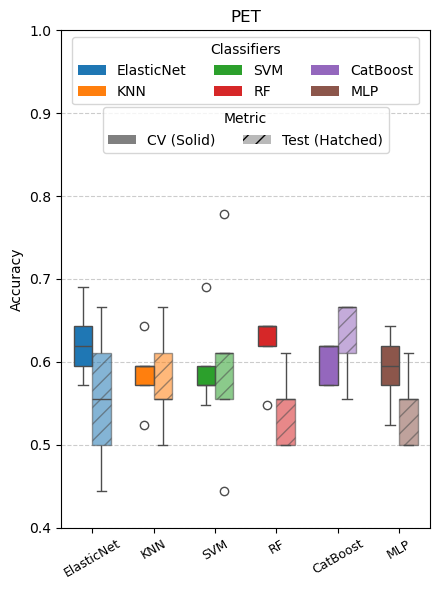

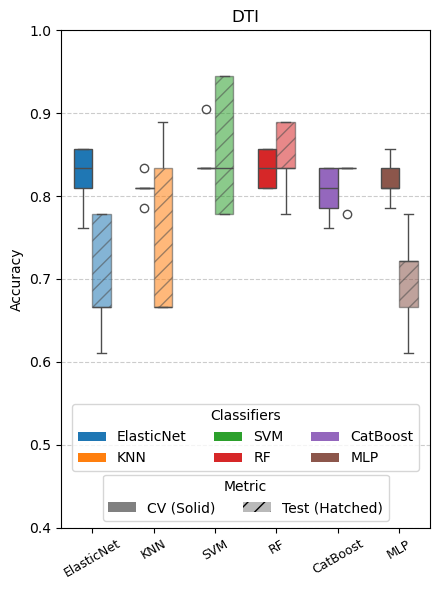

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from matplotlib.patches import Patch

# ══════════════════════════════════════════════════════════════════════
# FIGURE 3 — 3 Subplots (One per Modality) with Classifier Colors
# ══════════════════════════════════════════════════════════════════════
MOD_TRANSLATE = {
    'Morfológicos': 'MRI',
    'Metabólicos':  'PET',
    'DTI':          'DTI'
}
# 1. Transform to long format
df_melted = df_all.melt(
    id_vars=['Modalidad', 'Modelo'],
    value_vars=['CV_Acc', 'Test_Acc'],
    var_name='Metric',
    value_name='Accuracy'
)

df_melted['Metric'] = df_melted['Metric'].replace({'CV_Acc': 'CV', 'Test_Acc': 'Test'})

# Map a fixed color to each classifier algorithm
base_palette = sns.color_palette('tab10', n_colors=len(ALGORITMOS))
color_map = {algo: base_palette[i] for i, algo in enumerate(ALGORITMOS)}

# 2. Generate an independent plot for each modality
for modal in MODALIDADES:
    modality = MOD_TRANSLATE[modal]
    df_sub = df_melted[df_melted['Modalidad'] == modal]
    
    fig, ax = plt.subplots(figsize=(4.5, 6))
    
    # Plot boxplot: X is Model, HUE is Metric (CV vs Test)
    sns.boxplot(
        data=df_sub,
        x='Modelo',
        y='Accuracy',
        hue='Metric',
        order=ALGORITMOS,
        hue_order=['CV', 'Test'],
        palette={'CV': 'gray', 'Test': 'gray'}, # Temporary base color
        width=0.6,
        ax=ax
    )
    
    # Customize patches: Apply classifier color and differentiate CV (solid) vs Test (hatched)
    boxes = [patch for patch in ax.patches if type(patch).__name__ == 'PathPatch']
    boxes = sorted(boxes, key=lambda p: p.get_extents().xmin) # Sort strictly left-to-right
    
    for idx, patch in enumerate(boxes):
        modelo_idx = idx // 2
        modelo_nombre = ALGORITMOS[modelo_idx]
        color = color_map[modelo_nombre]
        
        es_test = (idx % 2 != 0)
        
        if es_test:
            patch.set_facecolor(color)
            patch.set_alpha(0.55)
            patch.set_hatch('//')
        else:
            patch.set_facecolor(color)
            patch.set_alpha(1.0)
            
    # Formatting
    ax.set_ylim(0.4, 1.0)
    ax.set_title(f'{modality}', fontsize=12)#, fontweight='bold', pad=10)
    ax.set_xlabel('')
    ax.set_ylabel('Accuracy', fontsize=10)# if modality=='MRI' else ''
    ax.grid(axis='y', alpha=0.4, color='gray', linestyle='--')
    ax.set_axisbelow(True)
    #if modality=='PET' or modality=='DTI':
    #    ax.tick_params(axis='y', left=False, labelleft=False)
    ax.tick_params(axis='x', rotation=30, labelsize=9)
    
    # Legend 1: Classifiers (Top inside plot)
    legend_modelos = [Patch(facecolor=color_map[algo], label=algo) for algo in ALGORITMOS]
    leg1 = ax.legend(
        handles=legend_modelos,
        title='Classifiers',
        loc='lower center' if modal=='DTI' else 'upper center',
        bbox_to_anchor=(0.5, 0.1 if modal == 'DTI' else 1.0),
        ncol=3
    )
    ax.add_artist(leg1)
    
    # Legend 2: Metric CV / Test (Just below Legend 1)
    legend_metricas = [
        Patch(facecolor='gray', alpha=1.0, label='CV (Solid)'),
        Patch(facecolor='gray', alpha=0.55, hatch='//', label='Test (Hatched)')
    ]
    ax.legend(
        handles=legend_metricas,
        title='Metric',
        loc='lower center' if modal=='DTI' else 'upper center',
        bbox_to_anchor=(0.5, 0 if modal == 'DTI' else 0.86),
        ncol=2
    )
    
    plt.tight_layout()
    filename = f"{OUT_DIR}/figuras/03_boxplot_{modal.lower().replace(' ', '_')}.png"
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    #plt.close()
    print(f'  ✅ Subfigure saved: {filename}')

  ✅ Fig 8 guardada: Ranking global modalidades


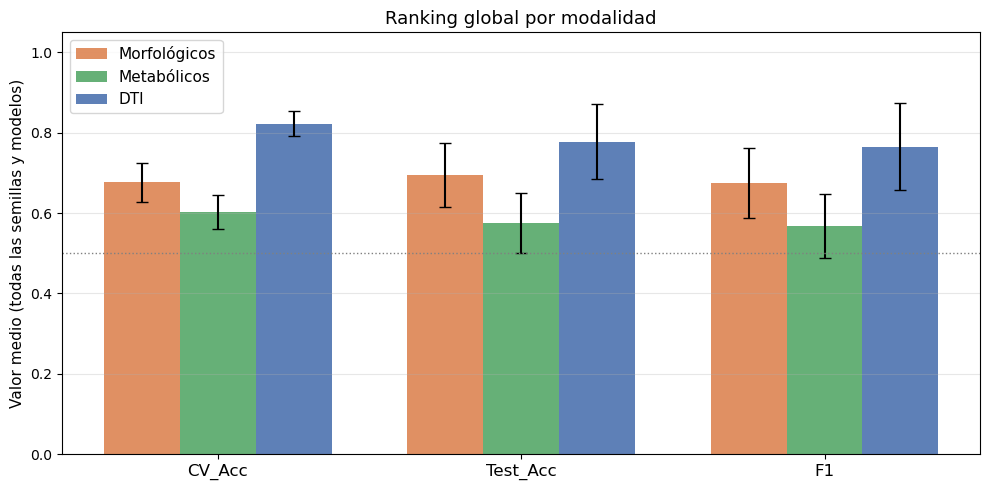

In [12]:
# ══════════════════════════════════════════════════════════════════════
# FIGURA 8 — Ranking de modalidades por métrica (barras agrupadas)
# ══════════════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(10, 5))
metricas_plot = ['CV_Acc', 'Test_Acc', 'F1']
x = np.arange(len(metricas_plot))
width = 0.25

for i, modo in enumerate(MODALIDADES):
    sub = df_all[df_all['Modalidad'] == modo]
    means = [sub[m].mean() for m in metricas_plot]
    stds  = [sub[m].std()  for m in metricas_plot]
    ax.bar(x + i*width, means, width, yerr=stds, capsize=4,
           label=modo, color=MOD_COLORS[modo], alpha=0.9)

ax.set_xticks(x + width)
ax.set_xticklabels(metricas_plot, fontsize=12)
ax.set_ylim(0, 1.05)
ax.axhline(1/2, color='gray', linestyle=':', lw=1)
ax.set_ylabel('Valor medio (todas las semillas y modelos)', fontsize=11)
ax.set_title('Ranking global por modalidad', fontsize=13)
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/figuras/08_ranking_modalidades.png', dpi=150)
#plt.close()
print('  ✅ Fig 8 guardada: Ranking global modalidades')



In [13]:
# ══════════════════════════════════════════════════════════════════════
# Tabla — Mejor modelo por modalidad (tabla visual)
# ══════════════════════════════════════════════════════════════════════
print('\n  Mejor modelo por modalidad (CV_Acc):')
best_rows = []
for modo in MODALIDADES:
    sub = df_all[df_all['Modalidad'] == modo]
    if sub.empty: continue
    best = sub.loc[sub['CV_Acc'].idxmax()]
    best_rows.append({
        'Modalidad': modo,
        'Modelo':    best['Modelo'],
        'Seed':      int(best['Seed']),
        'Selector':  best['Selector'],
        'k':         int(best['k']),
        'Train Acc.':  round(best['CV_Acc'], 4),
        'Accuracy':    round(best['Test_Acc'], 4),
        'Precision':   round(best['Precision'], 4),
        'Sensibilidad':round(best['Recall'], 4),
        'F1':          round(best['F1'], 4),
    })
df_best = pd.DataFrame(best_rows)
print(df_best.to_string(index=False))
df_best.to_csv(f'{OUT_DIR}/tablas/mejor_modelo_por_modalidad.csv', index=False)


  Mejor modelo por modalidad (CV_Acc):
   Modalidad     Modelo  Seed                         Selector  k  Train Acc.  Accuracy  Precision  Sensibilidad     F1
Morfológicos ElasticNet    21 FromModel_RandomForestClassifier 12      0.7857    0.6111     0.5972        0.6111 0.5937
 Metabólicos        SVM     7        KBest_mutual_info_classif 24      0.6905    0.6111     0.6048        0.6111 0.6049
         DTI        SVM    28        KBest_mutual_info_classif 24      0.9048    0.7778     0.8667        0.7778 0.7500


In [20]:
# ══════════════════════════════════════════════════════════════════════
# Tabla — Top 3 mejores modelos por modalidad (tabla visual)
# ══════════════════════════════════════════════════════════════════════
print('\n  Top 3 mejores modelos por modalidad (Test_Acc):')
best_rows = []

for modo in MODALIDADES:
    sub = df_all[df_all['Modalidad'] == modo]
    if sub.empty: continue
    
    # Ordenamos explícitamente por Test_Acc, desempatando con CV_Acc y F1 (de mayor a menor)
    top3 = sub.sort_values(
        by=['Test_Acc', 'CV_Acc', 'F1'], 
        ascending=[False, False, False]
    ).head(3)
    
    # Iteramos sobre esas 3 mejores filas, llevando un contador para el Rank
    for rank, (_, best) in enumerate(top3.iterrows(), start=1):
        best_rows.append({
            'Modalidad': modo,
            'Rank':      rank,
            'Modelo':    best['Modelo'],
            'Seed':      int(best['Seed']),
            'Selector':  best['Selector'],
            'k':         int(best['k']),
            'Train Acc.':  round(best['CV_Acc'], 4),
            'Accuracy':    round(best['Test_Acc'], 4),
            'Precision':   round(best['Precision'], 4),
            'Sensibilidad':round(best['Recall'], 4),
            'F1':          round(best['F1'], 4),
        })

df_best = pd.DataFrame(best_rows)
print(df_best.to_string(index=False))

# Guardamos el CSV actualizado
df_best.to_csv(f'{OUT_DIR}/tablas/top3_modelos_por_modalidad.csv', index=False)


  Top 3 mejores modelos por modalidad (Test_Acc):
   Modalidad  Rank     Modelo  Seed                  Selector  k  Train Acc.  Accuracy  Precision  Sensibilidad     F1
Morfológicos     1        SVM    21           KBest_f_classif 24      0.7143    0.8333     0.8333        0.8333 0.8333
Morfológicos     2        SVM     7           KBest_f_classif 24      0.6905    0.8333     0.8571        0.8333 0.8308
Morfológicos     3 ElasticNet    14           KBest_f_classif 24      0.7381    0.7778     0.7825        0.7778 0.7766
 Metabólicos     1        SVM    35 KBest_mutual_info_classif 12      0.5952    0.7778     0.7738        0.7778 0.7641
 Metabólicos     2 ElasticNet    35           KBest_f_classif 24      0.6429    0.6667     0.6667        0.6667 0.6667
 Metabólicos     3   CatBoost    28 KBest_mutual_info_classif 24      0.6190    0.6667     0.6750        0.6667 0.6623
         DTI     1        SVM    35           KBest_f_classif 48      0.8333    0.9444     0.9524        0.9444 0.94

In [21]:
# Cargar la tabla que acabamos de generar
df_tabla = df_best
# Seleccionar y renombrar las columnas con la notación matemática correcta
df_latex = df_tabla[['Modalidad', 'Rank', 'Modelo', 'Selector', 'k', 'Train Acc.', 'Accuracy', 'Precision', 'Sensibilidad', 'F1']].copy()
df_latex.columns = ['Modality', 'Rank', 'Model', 'Selector', 'k',  'Tr. Acc.', 'Accuracy', 'Precision', 'Recall', 'F1']

# Exportar directamente a un archivo .tex listo para incluir o copiar
codigo_latex = df_latex.to_latex(
    index=False,
    float_format="%.4f",       # Redondea automáticamente todos los decimales a 4 posiciones
    bold_rows=False,
    column_format='lllccccccc',   # Alineación de columnas (l=left, c=center)
    caption='Top 3 de modelos unimodales para MRI, PET y DTI.',
    label='tab:top3_unimodales',
    position='htbp',
    na_rep='—'                 # Reemplaza los valores vacíos/NaN por la raya formal
)

#with open(f'{OUT_DIR}/tablas/tabla_resultados.tex', 'w', encoding='utf-8') as f:
#    f.write(codigo_latex)
#print("✅ Código LaTeX exportado automáticamente de forma nativa.")
print(codigo_latex)

\begin{table}[htbp]
\caption{Top 3 de modelos unimodales para MRI, PET y DTI.}
\label{tab:top3_unimodales}
\begin{tabular}{lllccccccc}
\toprule
Modality & Rank & Model & Selector & k & Tr. Acc. & Accuracy & Precision & Recall & F1 \\
\midrule
Morfológicos & 1 & SVM & KBest_f_classif & 24 & 0.7143 & 0.8333 & 0.8333 & 0.8333 & 0.8333 \\
Morfológicos & 2 & SVM & KBest_f_classif & 24 & 0.6905 & 0.8333 & 0.8571 & 0.8333 & 0.8308 \\
Morfológicos & 3 & ElasticNet & KBest_f_classif & 24 & 0.7381 & 0.7778 & 0.7825 & 0.7778 & 0.7766 \\
Metabólicos & 1 & SVM & KBest_mutual_info_classif & 12 & 0.5952 & 0.7778 & 0.7738 & 0.7778 & 0.7641 \\
Metabólicos & 2 & ElasticNet & KBest_f_classif & 24 & 0.6429 & 0.6667 & 0.6667 & 0.6667 & 0.6667 \\
Metabólicos & 3 & CatBoost & KBest_mutual_info_classif & 24 & 0.6190 & 0.6667 & 0.6750 & 0.6667 & 0.6623 \\
DTI & 1 & SVM & KBest_f_classif & 48 & 0.8333 & 0.9444 & 0.9524 & 0.9444 & 0.9441 \\
DTI & 2 & SVM & KBest_f_classif & 60 & 0.8333 & 0.9444 & 0.9524 & 0.9444

  ✅ Fig 5 guardada: Selector y k unificados


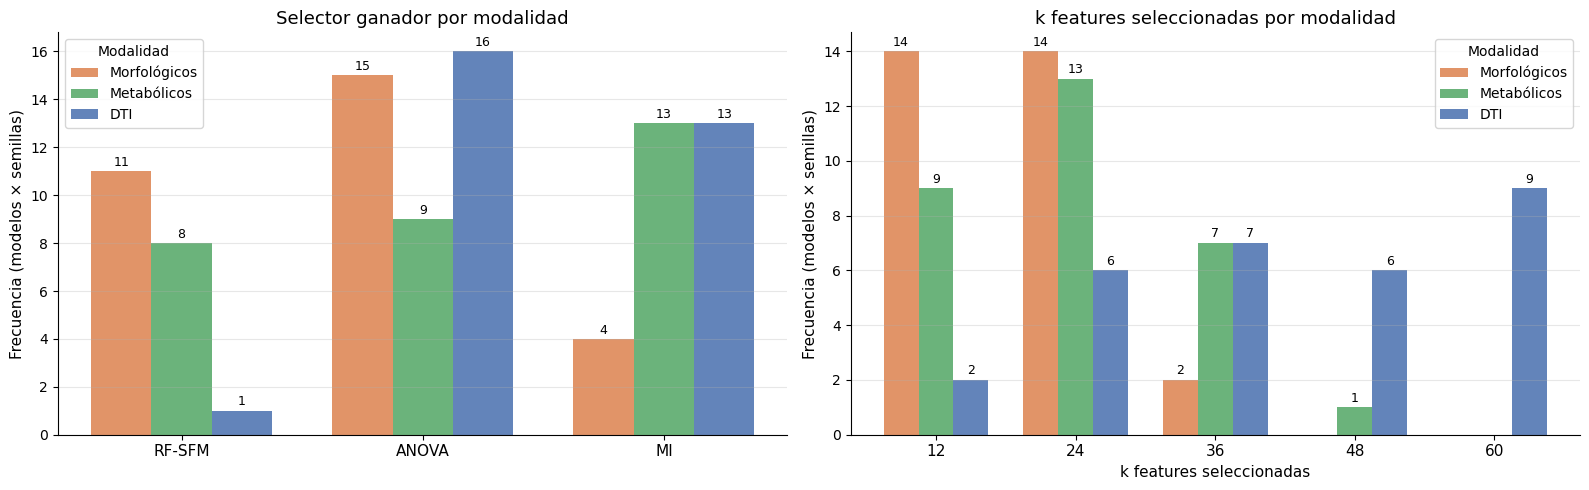

In [16]:
figura_selector_k_unificada(OUT_DIR, MODALIDADES, dfs_por_modalidad)



  ✅ Archivo consolidado guardado en: Morfológicos/biomarcadores_consolidados_Morfológicos.csv
  ✅ Archivo consolidado guardado en: Metabólicos/biomarcadores_consolidados_Metabólicos.csv
  ✅ Archivo consolidado guardado en: DTI/biomarcadores_consolidados_DTI.csv
  ✅ Fig 9 guardada: Top 10 ROIs todas las modalidades


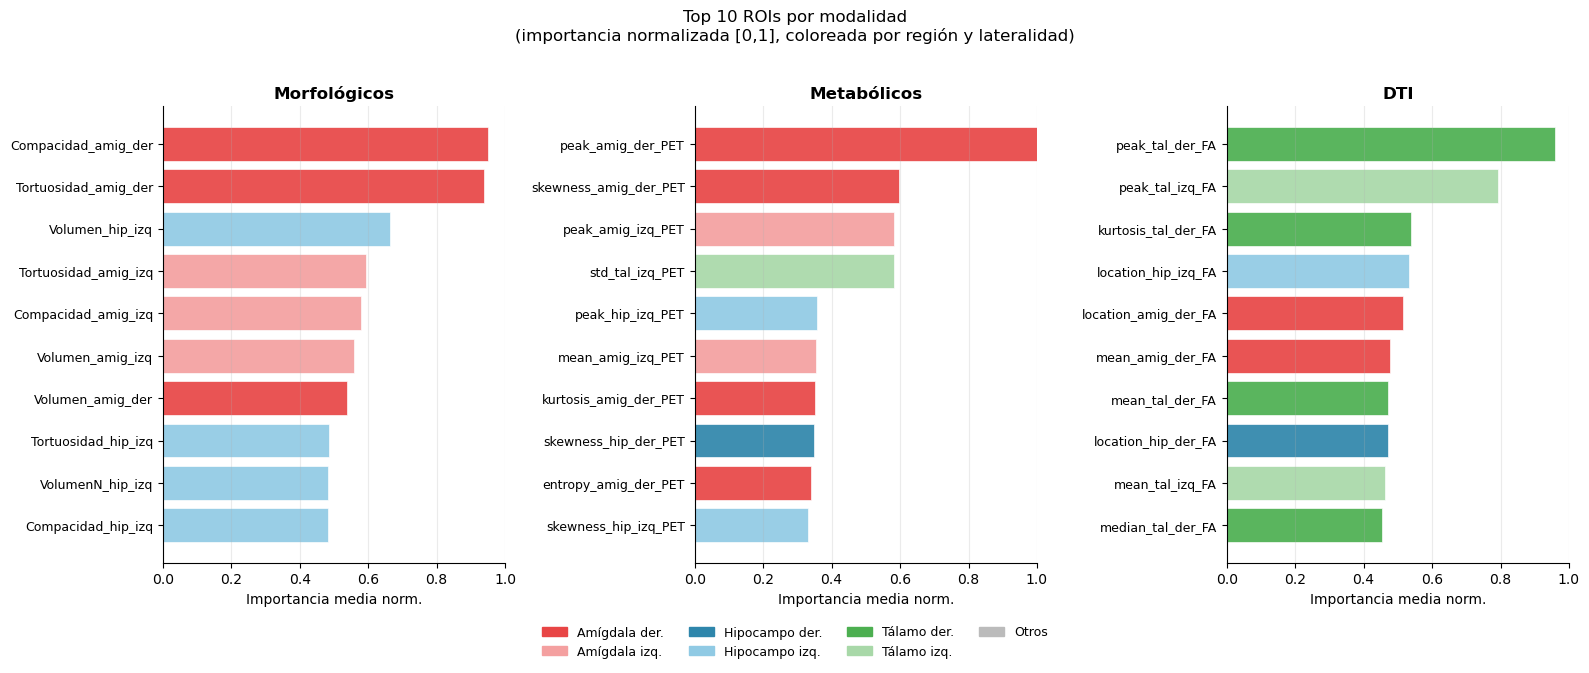

In [17]:
figura_top10_todas_modalidades(OUT_DIR, MODALIDADES)

In [18]:
print(f'\n{"═"*55}')
print(f'  ✅ Análisis completado.')
print(f'  📁 Salidas en: {OUT_DIR}/')
print(f'{"═"*55}')


═══════════════════════════════════════════════════════
  ✅ Análisis completado.
  📁 Salidas en: resultados_unimodales/
═══════════════════════════════════════════════════════
